In [1]:
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"

# os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform" 
# This makes JAX allocate exactly what is needed on demand, and deallocate memory that is no longer needed (note that this is the only configuration that will deallocate GPU memory, instead of reusing it). This is very slow, so is not recommended for general use, but may be useful for running with the minimal possible GPU memory footprint or debugging OOM failures.

os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".95"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import jax
import jax.numpy as jnp
from jax import random
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
from flax import linen as nn
import optax
import jax
import jax.numpy as jnp
from jax import random, jit
import optax
from tqdm import tqdm
import matplotlib.pyplot as plt
# Assuming equivalent JAX implementations
from src.subspace_curve import pytree_to_matrix
import wandb
from src.models import ResNet, ResNetBlock, init_t_lambda_to_phi, init_model_tube, init_model_phi
from jax_tqdm import scan_tqdm
from torch.utils.data import random_split
import torch
#import torchvision
from torch.utils.data import TensorDataset
import pandas as pd
from src.models import MLPModel


%load_ext autoreload
%autoreload 2

# %env XLA_FLAGS="--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = ('--xla_force_host_platform_device_count=10 '
#                            '--xla_dump_to=xla_dump/')
%env XLA_FLAGS

#jax.devices("gpu")

'--xla_force_host_platform_device_count=10'

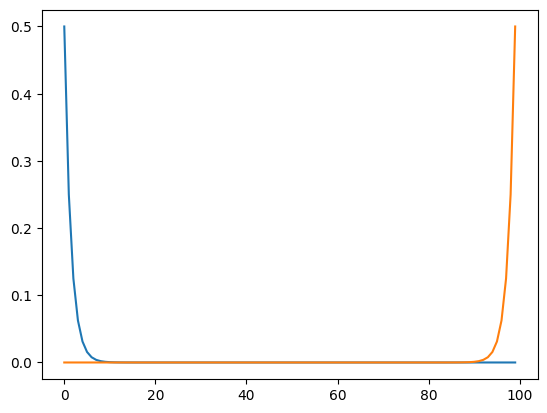

In [4]:
M = 100
def pi_kl(M, i):
    return 2**(M-i) / (2**M -1)

def pi_kls2(M, i):
    return 2**((i % M) + 1) / (2 ** (M + 1) - 1)    

kls = [pi_kl(M, i+1) for i in range(M)]
kls2 = [pi_kls2(M, i) for i in range(M)]
plt.plot(kls)
plt.plot(kls2)

In [3]:
sum(kls)

1.0

In [5]:
sum(kls2)

1.0

In [11]:
test = jnp.linspace(0, 20, num=20, dtype=jnp.bfloat16).reshape((5,4))

test.device

CudaDevice(id=0)

In [12]:
test

Array([[0, 1.05469, 2.10938, 3.15625],
       [4.21875, 5.28125, 6.3125, 7.375],
       [8.4375, 9.5, 10.5625, 11.625],
       [12.625, 13.6875, 14.75, 15.8125],
       [16.875, 17.875, 19, 20]], dtype=bfloat16)

In [15]:
test_cpu = jax.device_put(test, jax.devices("cpu")[0]).astype(jnp.float32)
test_cpu.device

CpuDevice(id=0)

In [17]:
jax.device_put(test_cpu, test.device).device

CudaDevice(id=0)

In [24]:
test = jnp.arange(20).reshape((5,4))

# @jit
def scanf(data, rng):
    idx = jax.random.choice(rng, 4, shape=(4,), replace=False)
    rng, rng_ = jax.random.split(rng)
    pos = jax.random.choice(rng_, data.shape[0], shape=(1,), replace=False)
    # jax.debug.print("idx: {idx}", idx=idx)
    # sel_data = data.at[idx]
    # sel_data = jax.lax.dynamic_index_in_dim(data, idx, axis=0, keepdims=False)
    sel_data = jnp.take(data, pos+idx-2, axis=0, mode='clip', fill_value=-1)
    return data, sel_data

rng = jax.random.PRNGKey(0)
keys = jax.random.split(rng, 3)
data, sel = jax.lax.scan(scanf, test, keys)
# scanf(test, keys[0])
sel

Array([[[ 8,  9, 10, 11],
        [16, 17, 18, 19],
        [12, 13, 14, 15],
        [16, 17, 18, 19]],

       [[ 0,  1,  2,  3],
        [ 8,  9, 10, 11],
        [ 0,  1,  2,  3],
        [ 4,  5,  6,  7]],

       [[16, 17, 18, 19],
        [12, 13, 14, 15],
        [ 8,  9, 10, 11],
        [16, 17, 18, 19]]], dtype=int32)

In [16]:
class Abstract:
    pass

class Config(Abstract):
    pass

class TrainState(Config):
    pass

print(isinstance(Config(), Abstract))
print(isinstance(Config(), TrainState))
print(isinstance(TrainState(), Abstract))
print(type(TrainState()) is Abstract)
print(type(TrainState()) is Config)
print(type(TrainState()) is TrainState)

True
False
True
False
False
True


In [5]:
def gen_data(rng_seed, net_kwargs, **kwargs):
    rng_key = random.PRNGKey(rng_seed + 1133)
    x = jnp.linspace(-2, 2, 100)
    x = x[(jnp.abs(x) > 0.6)].reshape(-1, 1)

    # define ground trouth model
    rng_key, rng_init = random.split(rng_key)
    model_gen = MLPModel(**net_kwargs)
    params = model_gen.init(rng_init, x)

    # generate train data
    y_gt = model_gen.apply(params, x).squeeze()
    rng_key, rng = random.split(rng_key)
    y = y_gt + jax.random.normal(rng, y_gt.shape) * 0.05

    # generate valid data
    x_val = jnp.linspace(-2, 2, 25)
    x_val = x_val[(jnp.abs(x_val) > 0.6)].reshape(-1, 1)
    y_gt_val = model_gen.apply(params, x_val).squeeze()
    rng_key, rng = random.split(rng_key)
    y_val = y_gt_val + jax.random.normal(rng, y_gt_val.shape) * 0.05

    xt = jnp.linspace(-2.5, 2.5, 1000).reshape(-1, 1)
    rng_key, rng = random.split(rng_key)
    y_gtt = model_gen.apply(params, xt).squeeze()
    yt = y_gtt + jax.random.normal(rng, y_gtt.shape) * 0.05

    return x, y, x_val, y_val, xt, yt, y_gtt

Data shapes: (70, 1) (70,) (18, 1) (1000, 1)


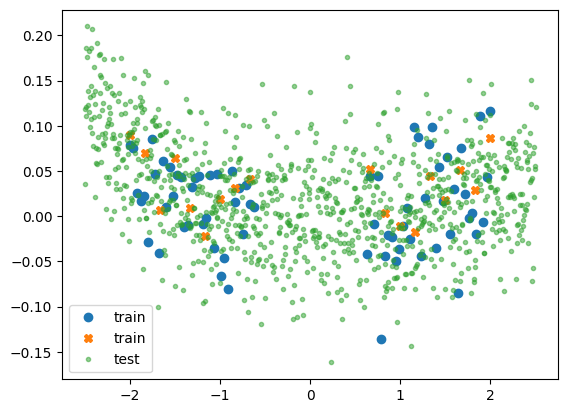

In [6]:
config = {'rng_seed': 0,
          'num_epochs': 500,
          'batch_size': 100,
          'optimizer_conf': {'name': "optax.sgd", 'kwargs': {'learning_rate': 0.05, 'momentum': 0.9, 'nesterov': True}},
          'net_kwargs': {'depth': 10, 'width': 10, 'activation': "relu"}}

x, y, x_val, y_val, xt, yt, y_gtt = gen_data(**config)
plt.plot(x, y, 'o', label='train')
plt.plot(x_val, y_val, 'X', label='train')
plt.plot(xt, yt, '.', label='test', alpha=0.5)
plt.legend()
print("Data shapes:", x.shape, y.shape, x_val.shape, xt.shape)


In [ ]:
from src.subspace_curve import CategorySubspace
from src.models import ResNet, ResNetBlock, MLPModel

temp_x = jnp.ones((10, 32, 32, 3))
temp_y = jax.random.randint(random.PRNGKey(0), (10,), 0, 3)
model = ResNet(num_classes=3, num_blocks=(1,), block_class=ResNetBlock, act_fn=nn.elu)

s_model = CategorySubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=True)
# mask['Dense_2']['bias'] = False  # do curve bias
# mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
s_model.set_train_mask(mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], params['batch_stats'], t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), 0.5, params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

(2, 16)
(2, 16)
(2, 3, 3, 3, 16)
(2, 3)
(2, 16, 3)
(2, 16)
(2, 16)
(2, 16)
(2, 16)
(2, 3, 3, 16, 16)
(2, 3, 3, 16, 16)
Out shape:  (10, 3)


Array(3.569724, dtype=float32)

In [ ]:
from src.subspace_curve import RegressionSubspace, DistRegressionSubspace, RepulsiveDistRegressionSubspace
temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')


s_model = DistRegressionSubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=True)
mask['Dense_2']['bias'] = False  # do curve bias
mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], {}, t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), 0.5, params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

{'Dense_0': {'bias': True, 'kernel': True}, 'Dense_1': {'bias': True, 'kernel': True}, 'Dense_2': {'bias': False, 'kernel': False}, 'Dense_3': {'bias': True, 'kernel': True}}
(2, 5)
(2, 3, 5)
(2, 5)
(2, 5, 5)
(5,)
(5, 5)
(2, 1)
(2, 5, 1)
()
Out shape:  (10, 1)


Array(1.2986622, dtype=float32)

{'mse_val_curve': Array(0.13259229, dtype=float32), 'nll_val_curve': Array(0.9252702, dtype=float32)}
{'mse_test_curve': Array(0.24132161, dtype=float32), 'nll_test_curve': Array(0.9877937, dtype=float32)}
{'mse_val_curve_last': Array(0.13259229, dtype=float32), 'nll_val_curve_last': Array(0.9252702, dtype=float32)}
{'mse_test_curve_last': Array(0.24132161, dtype=float32), 'nll_test_curve_last': Array(0.9877937, dtype=float32)}


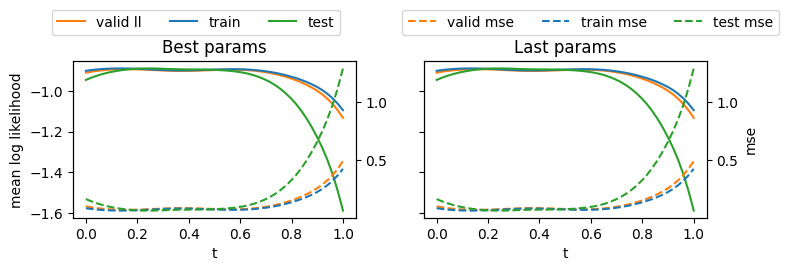

In [99]:
from toyReg_PtoC import setup_metrics

fig, ax = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
t_space = jnp.linspace(0, 1, 50)
valid_metrics_fn_final = setup_metrics(s_model, 18, x_val, y_val, n_samples=50, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(s_model, 70, x, y, n_samples=50, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(s_model, 250, xt, yt, n_samples=50, use_linspace=True, average=False)

# valid
rng_key = random.PRNGKey(0)
nll, mse = valid_metrics_fn_final(rng_key, params)
print({'mse_val_curve': mse.mean(), 'nll_val_curve': nll.mean()})
ax[0].plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax[0].twinx()
ax2.plot(t_space, mse, label="valid mse",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, mse = train_metrics_fn_final(rng_key, params)
ax[0].plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, mse, label="train mse",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, mse = test_metrics_fn_final(rng_key, params)
print({'mse_test_curve': mse.mean(), 'nll_test_curve': nll.mean()})
ax[0].plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, mse, label="test mse",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax[0].set_xlabel("t")
ax[0].set_ylabel("mean log likelihood")
ax[0].set_title("Best params")

# valid
last_params = params
nll, mse = valid_metrics_fn_final(rng_key, last_params)
print({'mse_val_curve_last': mse.mean(), 'nll_val_curve_last': nll.mean()})
ax[1].plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax[1].twinx()
ax2.plot(t_space, mse, label="valid mse",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, mse = train_metrics_fn_final(rng_key, last_params)
ax[1].plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, mse, label="train mse",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, mse = test_metrics_fn_final(rng_key, last_params)
print({'mse_test_curve_last': mse.mean(), 'nll_test_curve_last': nll.mean()})
ax[1].plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, mse, label="test mse",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax[1].set_xlabel("t")
ax2.set_ylabel("mse")
ax[0].legend(loc='center left', bbox_to_anchor=(-0.1, 1.25), ncol=3)
ax[1].set_title("Last params")
ax2.legend(loc='center left', bbox_to_anchor=(-0.1, 1.25), ncol=3)
plt.tight_layout()

In [ ]:
from src.subspace_curve import RegressionSubspace, DistRegressionSubspace, RepulsiveDistRegressionSubspace, RepulsiveRegressionSubspace
temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')


s_model = RepulsiveDistRegressionSubspace(
    model=model,
    k=0,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False,
    regularizer = "cosine"
)
mask = s_model.init_mask(temp_x, all_curves=False)
mask['Dense_2']['bias'] = True  # do curve bias
mask['Dense_2']['kernel'] = True  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], {}, t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), 0.5, params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

{'Dense_0': {'bias': False, 'kernel': False}, 'Dense_1': {'bias': False, 'kernel': False}, 'Dense_2': {'bias': True, 'kernel': True}, 'Dense_3': {'bias': False, 'kernel': False}}
(5,)
(3, 5)
(5,)
(5, 5)
(1, 5)
(1, 5, 5)
(1,)
(5, 1)
()
Out shape:  (10, 1)


Array(1.1795386, dtype=float32)

In [ ]:
from copy import deepcopy

temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')
init_params = model.init(random.PRNGKey(0), temp_x)

s_model = RepulsiveRegressionSubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False,
    regularizer = "cosine"
)
mask = s_model.init_mask(temp_x, all_curves=False)
mask['Dense_2']['bias'] = True  # do curve bias
mask['Dense_2']['kernel'] = True  # do curve kernel

params = s_model.init_params_from_point(key=random.PRNGKey(0), point=init_params, mask=mask, noise_fn=lambda p, key: p+1e-6*jax.random.normal(key, p.shape, dtype=p.dtype))

for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)

params['params']['Dense_2']['bias']

(5,)
(3, 5)
(5,)
(5, 5)
(2, 5)
(2, 5, 5)
(1,)
(5, 1)


Array([[-2.6328860e-07,  1.2015249e-06,  3.9223087e-09,  5.9714375e-07,
        -5.8692882e-07],
       [ 5.5833033e-07,  2.2071972e-06, -6.3644217e-07, -9.0532609e-07,
         1.3979794e-06]], dtype=float32)

In [74]:
init_params['params']['Dense_2']['bias']

Array([0., 0., 0., 0., 0.], dtype=float32)

In [91]:
jnp.linspace(0, 1., 1)

Array([0.], dtype=float32)

In [ ]:
from src.subspace_curve import CategorySubspace

temp_x = jnp.ones((10, 32, 32, 3))
temp_y = jax.random.randint(random.PRNGKey(0), (10,), 0, 3)
model = ResNet(num_classes=3, num_blocks=(1,), block_class=ResNetBlock, act_fn=nn.elu)

s_model = CategorySubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=True)
# mask['Dense_2']['bias'] = False  # do curve bias
# mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], params['batch_stats'], t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), 0.5, params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

(2, 16)
(2, 16)
(2, 3, 3, 3, 16)
(2, 3)
(2, 16, 3)
(2, 16)
(2, 16)
(2, 16)
(2, 16)
(2, 3, 3, 16, 16)
(2, 3, 3, 16, 16)
Out shape:  (10, 3)


Array(3.569724, dtype=float32)

In [83]:
from copy import deepcopy
def mask_as_no_curve(mask, *key_names):
    """Convert a mask to a no-curve mask according key_name. 
    Note: Function opperates in-place."""
    # All names are checked
    if len(key_names) == 0:
        return mask
    def key_in_path(path):
        return all(k in path for k in set(key_names)) 
          
    path_values, structure = jax.tree_util.tree_flatten_with_path(mask)
    new_mask = jax.tree.leaves(mask)
    for i, (k, v) in enumerate(path_values):
        path = "/".join((dk.key for dk in k))
        if key_in_path(path):
            new_mask[i] = False
    return jax.tree.unflatten(structure, new_mask)

mask2 = mask_as_no_curve(deepcopy(mask), "BatchNorm", 'scale')
mask2


{'BatchNorm_0': {'bias': True, 'scale': False},
 'Conv_0': {'kernel': True},
 'Dense_0': {'bias': True, 'kernel': True},
 'ResNetBlock_0': {'BatchNorm_0': {'bias': True, 'scale': False},
  'BatchNorm_1': {'bias': True, 'scale': False},
  'Conv_0': {'kernel': True},
  'Conv_1': {'kernel': True}}}

In [84]:
params = s_model.init_params(random.PRNGKey(0), temp_x, mask2)
for p in jax.tree.leaves(params['params']):
    print(p.shape)

(2, 16)
(16,)
(2, 3, 3, 3, 16)
(2, 3)
(2, 16, 3)
(2, 16)
(16,)
(2, 16)
(16,)
(2, 3, 3, 16, 16)
(2, 3, 3, 16, 16)


In [85]:
mask2 = mask_as_no_curve(deepcopy(mask), *[])
mask2

{'BatchNorm_0': {'bias': True, 'scale': True},
 'Conv_0': {'kernel': True},
 'Dense_0': {'bias': True, 'kernel': True},
 'ResNetBlock_0': {'BatchNorm_0': {'bias': True, 'scale': True},
  'BatchNorm_1': {'bias': True, 'scale': True},
  'Conv_0': {'kernel': True},
  'Conv_1': {'kernel': True}}}

### LoRA

In [148]:
from src.subspace_curve import filter_mask, RegressionSubspace
from src.models import MLPModel

config = {
    'input_dim': 5,
    'n_samples': 5120,  # Will be made divisible by batch_size
    'batch_size': 256,
    'k': 2,  # Number of curve parameters (k+1 control points)
    'num_epochs': 5,
    'learning_rate': 1e-3,
    'weight_decay': 1e-4,
    'model_depth': 3,
    'model_width': 6,
}
key = random.PRNGKey(0)
dummy_input = jnp.ones((config['batch_size'], config['input_dim']))

base_model = MLPModel(
    depth=config['model_depth'], 
    width=config['model_width'], 
    activation="relu"
)

s_model = RegressionSubspace(
    model=base_model,
    k=config['k'],
    weight_decay=config['weight_decay']
)

key, subkey = random.split(key)
mask = s_model.init_mask(dummy_input, all_curves=False)
mask = filter_mask(mask, "kernel", as_curve=True, BoolschenOperator=all)
curve_params = s_model.init_params(subkey, dummy_input, mask)
s_model.set_train_mask(mask)
print(f"Memory Size for params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(curve_params)])/(1024**2):.4f}MB")


Memory Size for params: 0.0020MB


In [149]:
jax.tree_util.tree_flatten_with_path(mask)[0]

[((DictKey(key='Dense_0'), DictKey(key='bias')), False),
 ((DictKey(key='Dense_0'), DictKey(key='kernel')), True),
 ((DictKey(key='Dense_1'), DictKey(key='bias')), False),
 ((DictKey(key='Dense_1'), DictKey(key='kernel')), True),
 ((DictKey(key='Dense_2'), DictKey(key='bias')), False),
 ((DictKey(key='Dense_2'), DictKey(key='kernel')), True),
 ((DictKey(key='Dense_3'), DictKey(key='bias')), False),
 ((DictKey(key='Dense_3'), DictKey(key='kernel')), True)]

In [33]:
arr = jnp.ones((10, 32, 16, 3))
# Move axes 1 and 2 to the end
result = jnp.moveaxis(arr, [1, 2], [-2, -1])
print(result.shape)

(10, 3, 32, 16)


In [ ]:
from jax.tree_util import register_pytree_node_class

@register_pytree_node_class
class LoRAParams:
    def __init__(self, A, B, w0, dims: tuple):
        self.A = A
        self.B = B
        self.w0 = w0
        self.dims = dims # tuple of indices where the LoRA parameters are applied e.g. (0, 1) for the first two axes

    @property
    def shape(self):
        return (self.A.shape, self.B.shape, self.w0.shape)
        
    def __repr__(self):
        # return f"LoRAParams(A={self.A.shape}, B={self.B.shape}, w0={self.w0.shape})"
        return f"LoRAParams(A={self.A}, B={self.B}, w0={self.w0}) with dims={self.dims})"
    
    def tree_flatten(self):
        children = (self.A, self.B, self.w0)
        aux_data = self.dims
        return children, aux_data

    @classmethod
    def tree_unflatten(cls, aux_data, children):
        A, B, w0 = children
        return cls(A, B, w0, aux_data)
    
    def apply(self):
        # print(f"Applying LoRA to {p.w0.shape} with A: {p.A.shape}, B: {p.B.shape}")
        w = jnp.matmul(self.B, self.A)  # Apply LoRA transformation
        w = jnp.moveaxis(w, [-2, -1], self.dims)  # Move the last two axes to the positions specified by m
        return w + self.w0 + 100  # Add the original parameter w0


In [167]:

pp = base_model.init(random.PRNGKey(0), dummy_input)

lora_mask = jax.tree.map(lambda m: np.array((0,1)) if m else False, mask) 

def initialize_lora_params(rng_key, lora_mask, params, rank=4):
    """
    Initialize LoRA parameters based on the base model and the provided LoRA mask.
    lora_masl of the form:
        'Dense_0': {
            'kernel': [1, 0],  # Apply Low Rank for kernel on dimension 1 and 0
            'bias': False,  # Do not use LoRA for bias
            }
    returns:
        w0_params: Parameters of the model used as w0 by LoRA.
        lora_params: Parameters of the model. LoRA marked parameters are tuples of (A, B) where:
            A: The low-rank matrix of shape (rank, param_shape[m[1]])
            B: The low-rank matrix of shape (param_shape[m[0]], rank)
            Non LoRA parameters are returned as is.
    """
    # Initialize the base model parameters
    mask_, structure = jax.tree_util.tree_flatten_with_path(lora_mask)
    def shape_builder(shape, r_dim):
        shape = list(shape)
        shape[r_dim] = rank
        return tuple(shape)

    lora_params = []
    for (key, m), p in zip(mask_, jax.tree.leaves(params)):
        param_name = '/'.join([k.key for k in key])
        # change to a lora param 
        if (type(m) != bool):
            assert p.ndim > 1, f"Param {param_name} cannot be used for LoRA. Too few dimensions for parameter with shape {p.shape}"
            assert p.ndim > np.max(m), f"Mask {m} incompatible with param {param_name} and shape {p.shape}"
            B = jnp.zeros(shape_builder(p.shape, m[1]), dtype=p.dtype)
            B = jnp.moveaxis(B, [m[0], m[1]], [-2, -1])  # Move the first axis to the last position
            rng_key, subkey = random.split(rng_key)
            A = jax.random.normal(subkey, shape_builder(p.shape, m[0]), dtype=p.dtype)
            A = jnp.moveaxis(A, [m[0], m[1]], [-2, -1])  # Move the first axis to the last position
            lora_params.append(LoRAParams(A=A, B=B, w0=p, dims=tuple(m)))  # Store A and B as a tuple
            # lora_params.append(dict(A=A, B=B))  # Store A and B
        else:
            lora_params.append(p)

    lora_params = jax.tree_util.tree_unflatten(structure, lora_params)
    return lora_params

lora_params = initialize_lora_params(random.PRNGKey(0), lora_mask, pp['params'])
lora_params['Dense_0']['kernel'].B.shape

(15, 4)

In [168]:

def show_example(structured):
  flat, tree = jax.tree.flatten(structured)
  unflattened = jax.tree.unflatten(tree, flat)
  print(f"{structured=}\n  {flat=}\n  {tree=}\n  {unflattened=}")

In [169]:
show_example(lora_params['Dense_0'])

structured={'bias': Array([0., 0., 0., 0., 0., 0.], dtype=float32), 'kernel': LoRAParams(A=[[-2.003785   -0.25242862  0.670781   -0.24748416 -0.8836176  -0.338196  ]
 [ 1.0410496  -0.47741464  0.39571118  0.838507   -0.90660936 -0.81707186]
 [ 0.43643975  1.4724442  -2.19621    -1.6121409   1.296409    1.8319693 ]
 [-0.9455706  -0.34352237  0.05459858  0.33989352 -0.74641544 -0.00806977]], B=[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]], w0=[[-0.08960447 -0.03062159  0.14343636  0.5353447  -0.52553445  0.57176524]
 [ 0.29641306 -0.22472511  0.09601499 -0.5319004   0.0590609  -0.49142253]
 [ 0.10842418 -0.45233554  0.01688243 -0.16115963  0.18163641 -0.11370913]
 [-0.20943877  0.0787871  -0.26889256 -0.1012808  -0.10340035 -0.02109799]
 [ 0.09154411 -0.2468658   0.17472154 -0.39422983 -0.44126278 -0.12967783]


In [177]:
from typing import Any, Callable

def tree_broadcast(prefix_tree: Any, full_tree: Any,
                   is_leaf: Callable[[Any], bool] | None = None
                  ) -> Any:
    """Alias of :func:`jax.tree.broadcast`."""
    # broadcast_prefix is not exported
    def broadcast_prefix(prefix_tree: Any, full_tree: Any,
                        is_leaf: Callable[[Any], bool] | None = None
                        ) -> list[Any]:
        """Broadcasts tree prefix leaves into the full set of leaves for a given full tree.

            Args:
            prefix_tree: a pytree that is a tree prefix of full_tree.
            full_tree: a pytree with the structure to broadcast the prefix leaves into.
            is_leaf: an optionally specified function that will be called at each
                flattening step. It should return a boolean, with true stopping the
                traversal and the whole subtree being treated as a leaf, and false
                indicating the flattening should traverse the current object.

            Returns:
            A list of leaves matching the expected count for the full tree,
            with the leaf of each prefix tree being duplicated to match the count of
            its corresponding subtree.
        """
        result = []
        num_leaves = lambda t: jax.tree.structure(t).num_leaves
        add_leaves = lambda x, subtree: result.extend([x] * num_leaves(subtree))
        jax.tree.map(add_leaves, prefix_tree, full_tree, is_leaf=is_leaf)
        return result
    broadcast_leaves = broadcast_prefix(prefix_tree, full_tree, is_leaf=is_leaf)
    return jax.tree.structure(full_tree).unflatten(broadcast_leaves)

new_curve_mask = tree_broadcast(mask, lora_params)
new_curve_mask

{'Dense_0': {'bias': False,
  'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))},
 'Dense_1': {'bias': False,
  'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))},
 'Dense_2': {'bias': False,
  'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))},
 'Dense_3': {'bias': False,
  'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))}}

In [178]:
def adapt_mask(mask):
    """Adapt the mask to LoRAParams."""
    if isinstance(mask, LoRAParams):
        # Do not use LoRA for w0 and B
        mask.B = False
        mask.w0 = False
        return mask
    else:
        # For other parameters, keep the mask as is
        return mask
jax.tree.map(lambda m: adapt_mask(m), new_curve_mask, is_leaf=lambda x: isinstance(x, LoRAParams))

{'Dense_0': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(0, 1))},
 'Dense_1': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(0, 1))},
 'Dense_2': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(0, 1))},
 'Dense_3': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(0, 1))}}

In [171]:
lora_mask

{'Dense_0': {'bias': False, 'kernel': array([0, 1])},
 'Dense_1': {'bias': False, 'kernel': array([0, 1])},
 'Dense_2': {'bias': False, 'kernel': array([0, 1])},
 'Dense_3': {'bias': False, 'kernel': array([0, 1])}}

In [172]:
lora_params

{'Dense_0': {'bias': Array([0., 0., 0., 0., 0., 0.], dtype=float32),
  'kernel': LoRAParams(A=[[-2.003785   -0.25242862  0.670781   -0.24748416 -0.8836176  -0.338196  ]
   [ 1.0410496  -0.47741464  0.39571118  0.838507   -0.90660936 -0.81707186]
   [ 0.43643975  1.4724442  -2.19621    -1.6121409   1.296409    1.8319693 ]
   [-0.9455706  -0.34352237  0.05459858  0.33989352 -0.74641544 -0.00806977]], B=[[0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]
   [0. 0. 0. 0.]], w0=[[-0.08960447 -0.03062159  0.14343636  0.5353447  -0.52553445  0.57176524]
   [ 0.29641306 -0.22472511  0.09601499 -0.5319004   0.0590609  -0.49142253]
   [ 0.10842418 -0.45233554  0.01688243 -0.16115963  0.18163641 -0.11370913]
   [-0.20943877  0.0787871  -0.26889256 -0.1012808  -0.10340035 -0.02109799]
   [ 0.09154411 -0.2468658   0.1

In [173]:
new_param_after_lora = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) else lp, lora_params, is_leaf=lambda x: isinstance(x, LoRAParams))

In [174]:
def p_print(p):
    print(f"Param with shape: {p.shape} \n{p}")

p_print(new_param_after_lora['Dense_0']['kernel'])

Param with shape: (15, 6) 
[[ 99.91039   99.969376 100.14343  100.53535   99.474464 100.57176 ]
 [100.29641   99.775276 100.096016  99.4681   100.05906   99.508575]
 [100.10842   99.54766  100.016884  99.83884  100.18163   99.88629 ]
 [ 99.79056  100.07879   99.73111   99.89872   99.8966    99.978905]
 [100.091545  99.753136 100.17472   99.605774  99.55874   99.87032 ]
 [ 99.914696  99.95447  100.277084  99.55801  100.50476   99.87204 ]
 [ 99.972466  99.94286   99.9001    99.94118   99.654274 100.1105  ]
 [100.05787  100.21725   99.727356 100.312256  99.55831  100.56766 ]
 [ 99.892044 100.26635   99.63259   99.8795    99.689224 100.250694]
 [100.22435  100.38336   99.675575  99.9543   100.36041   99.977264]
 [100.11427   99.825386 100.18779   99.801315  99.96805   99.82157 ]
 [100.5371   100.15871   99.81987   99.79393  100.13431   99.94165 ]
 [ 99.92555  100.25053  100.333984  99.83026   99.74415   99.86343 ]
 [100.16874   99.92303  100.338745 100.124725 100.25223  100.131966]
 [ 99.7

In [175]:
p_print(pp['params']['Dense_0']['kernel'])

Param with shape: (15, 6) 
[[-0.08960447 -0.03062159  0.14343636  0.5353447  -0.52553445  0.57176524]
 [ 0.29641306 -0.22472511  0.09601499 -0.5319004   0.0590609  -0.49142253]
 [ 0.10842418 -0.45233554  0.01688243 -0.16115963  0.18163641 -0.11370913]
 [-0.20943877  0.0787871  -0.26889256 -0.1012808  -0.10340035 -0.02109799]
 [ 0.09154411 -0.2468658   0.17472154 -0.39422983 -0.44126278 -0.12967783]
 [-0.08530545 -0.04553502  0.27708718 -0.44199055  0.50476223 -0.12796202]
 [-0.02753122 -0.05713308 -0.09990036 -0.05882085 -0.34572795  0.11049813]
 [ 0.05787119  0.21724412 -0.2726415   0.31225553 -0.44168806  0.5676563 ]
 [-0.10795441  0.26634687 -0.36741188 -0.12050005 -0.31077823  0.2506951 ]
 [ 0.22435302  0.38335964 -0.32442155 -0.04570077  0.3604143  -0.02273644]
 [ 0.11427595 -0.1746155   0.18779275 -0.19868468 -0.03195056 -0.17842999]
 [ 0.5371035   0.15870318 -0.18013199 -0.20607124  0.1343083  -0.05834958]
 [-0.07444844  0.25052777  0.33398667 -0.16973855 -0.25584915 -0.13657153

In [ ]:

def get_params_from_lora(lora_params, lora_mask, non_lora_params):
    """    Apply LoRA transformations to the parameters based on the provided LoRA mask.
    Args:
        lora_params: LoRA parameters with leaves, which are instances of LoRAParams or similar structures
        lora_mask: A mask originally indicating which parameters should be transformed by LoRA and which marks the dimensions used
        non_lora_params: Non-LoRA parameters that should remain unchanged
    Returns:
        A new set of parameters where LoRA transformations have been applied according to the mask.
    """
    def apply_lora(p, m):
        if isinstance(p, LoRAParams):
            # print(f"Applying LoRA to {p.w0.shape} with A: {p.A.shape}, B: {p.B.shape}")
            w = jnp.matmul(p.B, p.A)  # Apply LoRA transformation
            w = jnp.moveaxis(w, [-2, -1], [m[0], m[1]])  # Move the last two axes to the positions specified by m
            return w + p.w0 # Add the original parameter w0
        else:
            return jnp.array([])
    
    new_param = jax.tree.map(lambda lp: lp.apply() if isinstance(lp, LoRAParams) lp, lora_params, lora_mask, is_leaf=lambda x: isinstance(x, LoRAParams))
    return jax.tree.map(lambda lp, p0, lm: p0 if isinstance(lm, bool) else lp, new_param, non_lora_params, lora_mask)


get_params_from_lora(lora_params, lora_mask, pp['params'])

{'Dense_0': {'bias': Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 

In [32]:
for p in jax.tree.leaves(lora_params, is_leaf=lambda x: isinstance(x, LoRAParams)):
    if isinstance(p, LoRAParams):
        print(p.A.shape)


(8, 640)
(8, 640)
(8, 640)
(8, 1)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)
(8, 640)


In [87]:
jax.tree.map(lambda m, p: p.shape, mask['Dense_0'], lora_params['Dense_0'])  # Check the shapes of A and B

AttributeError: 'dict' object has no attribute 'shape'

In [11]:
from flax.core import freeze, unfreeze
train_params = jax.tree.map(lambda x, m: x if m else jnp.array([]), curve_params['params'], mask)
freezed_params = freeze(jax.tree.map(lambda x, m: x if not m else jnp.array([]), curve_params['params'], mask))
train_params
print(f"Memory Size for params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(train_params)])/(1024**2):.4f}MB")
print(f"Memory Size for params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(freezed_params)])/(1024**2):.4f}MB")


joind_param = jax.tree.map(lambda x, y, m: x if m else y, train_params, unfreeze(freezed_params), mask)
joind_param

Memory Size for params: 0.7324MB
Memory Size for params: 154.7266MB


{'Dense_0': {'bias': Array([[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]], dtype=float32),
  'kernel': Array([[ 0.18383723,  0.00903161,  0.13324465, ..., -0.02975856,
          -0.38788745, -0.17457238],
         [-0.11258955,  0.03140361, -0.1072474 , ..., -0.14205085,
          -0.20866896,  0.39018857],
         [ 0.15409935, -0.00770645, -0.47568315, ..., -0.02105703,
           0.15163518,  0.5819677 ],
         ...,
         [ 0.1702801 ,  0.0229908 , -0.20456418, ..., -0.27516606,
           0.3887684 , -0.4197271 ],
         [ 0.3451644 , -0.06580606,  0.34879813, ...,  0.38451833,
          -0.10458014,  0.46489754],
         [ 0.30355498,  0.23436931,  0.28049138, ...,  0.0046455 ,
          -0.2479487 ,  0.16659008]], dtype=float32)},
 'Dense_1': {'bias': Array([[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]], dtype=float32),
  'kernel': Array([[-0

### Lora Subspace test

In [ ]:
from src.subspace_curve import filter_mask, RegressionSubspace, LoRAMixin
from src.models import MLPModel

class RegLoraSubspace(LoRAMixin, RegressionSubspace):
    pass

config = {
    'input_dim': 5,
    'n_samples': 5120,  # Will be made divisible by batch_size
    'batch_size': 256,
    'k': 2,  # Number of curve parameters (k+1 control points)
    'num_epochs': 5,
    'learning_rate': 1e-3,
    'weight_decay': 1e-4,
    'model_depth': 3,
    'model_width': 6,
}
key = random.PRNGKey(0)
dummy_input = jnp.ones((config['batch_size'], config['input_dim']))

base_model = MLPModel(
    depth=config['model_depth'], 
    width=config['model_width'], 
    activation="relu"
)
base_params = base_model.init(random.PRNGKey(0), dummy_input)

curve_mask = jax.tree.map(lambda x: False, base_params['params'])
curve_mask = filter_mask(curve_mask, "kernel", as_curve=True, BoolschenOperator=all)
train_mask = jax.tree.map(lambda x: True, curve_mask)
lora_mask = jax.tree.map(lambda m: np.array([1,0]) if m else m, curve_mask)  # LoRA for curve parameters only

s_model = RegLoraSubspace(
    r=4, # LoRA rank
    lora_mask=lora_mask,
    model=base_model,
    k=config['k'],
    weight_decay=config['weight_decay'],
    out_dist_log_scale=jnp.log(1.),  # Initial log scale for the output distribution
)

key, subkey = random.split(key)
curve_params = s_model.init_params_from_point(subkey, point=base_params, mask=curve_mask, noise_fn=lambda p, key: p+1.*jax.random.normal(key, p.shape, dtype=p.dtype))

# set and update train mask
train_mask = s_model.update_mask_for_lora(train_mask, curve_params['params'], b_off=False, w0_off=True) # w0 must be off for LoRA 
s_model.set_train_mask(train_mask)


print(f"Memory Size for params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(curve_params)])/(1024**2):.4f}MB")


Memory Size for params: 0.0025MB


In [20]:
s_model.curve_mask

{'Dense_0': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(1, 0))},
 'Dense_1': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(1, 0))},
 'Dense_2': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(1, 0))},
 'Dense_3': {'bias': False,
  'kernel': LoRAParams(A=True, B=False, w0=False) with dims=(1, 0))}}

In [21]:
s_model.train_mask

{'Dense_0': {'bias': True,
  'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0))},
 'Dense_1': {'bias': True,
  'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0))},
 'Dense_2': {'bias': True,
  'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0))},
 'Dense_3': {'bias': True,
  'kernel': LoRAParams(A=True, B=True, w0=False) with dims=(1, 0))}}

In [22]:
lora_mask

{'Dense_0': {'bias': False, 'kernel': array([1, 0])},
 'Dense_1': {'bias': False, 'kernel': array([1, 0])},
 'Dense_2': {'bias': False, 'kernel': array([1, 0])},
 'Dense_3': {'bias': False, 'kernel': array([1, 0])}}

In [23]:
curve_params

{'params': {'Dense_0': {'bias': Array([0., 0., 0., 0., 0., 0.], dtype=float32),
   'kernel': LoRAParams(A=[[[-0.18175352 -2.7053058  -1.4259737   1.6527019   0.49156222
       0.26582587  2.3953867   0.68606734 -0.2173087   0.32603467
       3.3478398  -0.79144317  2.4192932  -0.29847506 -0.01388878]
     [ 1.5419369  -2.2945766   1.162157   -2.7157087   1.10718
       2.4862423   1.552263   -1.6454508   0.8401059   1.3486211
      -2.3669827   0.7255432   0.14022505 -1.8745542  -0.91457707]
     [-0.61997384 -2.828744    2.634354    1.3083965  -0.08568519
       2.2331514  -0.5446385   2.1191022   0.3674601   2.1968179
       2.4256053   4.02513     0.623718   -1.9690409  -0.9345256 ]
     [ 1.1050836   0.92654747 -1.0777702  -2.9777231   0.23140061
       0.16398585 -0.7576222   0.9797719   0.7896349  -0.4900395
      -0.4517238   0.41893867  0.15679373 -0.8025273   0.5156873 ]]
   
    [[-1.0643061  -1.5344746   0.6074752  -0.77127635  1.702738
      -1.1119449   1.1662741   1.13669

In [24]:
curve_params['params']['Dense_0']['kernel'].shape

{'A': (3, 4, 15), 'B': (6, 4), 'w0': (15, 6)}

In [7]:
curve_params['params']['Dense_0']['kernel'].shape

{'A': (3, 4, 6), 'B': (15, 4), 'w0': (15, 6)}

In [25]:
only_train_params = s_model.only_trainable_params(curve_params['params'])
print(f"Memory Size for trainable params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(only_train_params)])/(1024**2):.4f}MB")

print(only_train_params['Dense_0']['kernel'])
print()
print("See w0 is not in trainable params:")
only_train_params['Dense_0']['kernel'].w0

Memory Size for trainable params: 0.0019MB
LoRAParams(A=[[[-0.18175352 -2.7053058  -1.4259737   1.6527019   0.49156222
    0.26582587  2.3953867   0.68606734 -0.2173087   0.32603467
    3.3478398  -0.79144317  2.4192932  -0.29847506 -0.01388878]
  [ 1.5419369  -2.2945766   1.162157   -2.7157087   1.10718
    2.4862423   1.552263   -1.6454508   0.8401059   1.3486211
   -2.3669827   0.7255432   0.14022505 -1.8745542  -0.91457707]
  [-0.61997384 -2.828744    2.634354    1.3083965  -0.08568519
    2.2331514  -0.5446385   2.1191022   0.3674601   2.1968179
    2.4256053   4.02513     0.623718   -1.9690409  -0.9345256 ]
  [ 1.1050836   0.92654747 -1.0777702  -2.9777231   0.23140061
    0.16398585 -0.7576222   0.9797719   0.7896349  -0.4900395
   -0.4517238   0.41893867  0.15679373 -0.8025273   0.5156873 ]]

 [[-1.0643061  -1.5344746   0.6074752  -0.77127635  1.702738
   -1.1119449   1.1662741   1.136694   -0.98784107  1.0091398
    3.3771117  -0.38624167  2.452095   -0.29276285  0.4129548 ]
 

Array([], shape=(0,), dtype=float32)

In [ ]:
only_train_params = s_model.only_trainable_params(curve_params['params'])
print(f"Memory Size for trainable params: {np.sum([l.size * l.itemsize for l in jax.tree.leaves(only_train_params)])/(1024**2):.4f}MB")

optimizer = optax.sgd(learning_rate=1e-2, momentum=0.9, nesterov=True)
opt_state = optimizer.init(only_train_params)

x_ = jax.random.normal(random.PRNGKey(3), (config['batch_size'], config['input_dim']))
y_ = jax.random.normal(random.PRNGKey(0), (config['batch_size'],))
loss, curve_params_update, opt_state, grad_ = s_model.train_step(
                    key, 0.5, curve_params, x_, y_, opt_state, optimizer)
loss

Memory Size for trainable params: 0.0019MB


Array(1.5620446, dtype=float32)

In [45]:
print("wo is the same as before: \n ", np.all(curve_params['params']['Dense_0']['kernel'].w0 == curve_params_update['params']['Dense_0']['kernel'].w0).item())

print("\n A differs: \n ", not np.any(curve_params['params']['Dense_0']['kernel'].A == curve_params_update['params']['Dense_0']['kernel'].A).item())

wo is the same as before: 
  True

 A differs: 
  True


In [31]:
p1 = curve_params['params']['Dense_0']['kernel']
p2 = curve_params_update['params']['Dense_0']['kernel']

p1.A - p2.A

Array([[[-6.85453415e-07, -1.02519989e-05, -5.36441803e-06,
          6.31809235e-06,  1.87754631e-06,  1.01327896e-06,
          9.05990601e-06,  2.62260437e-06, -8.19563866e-07,
          1.25169754e-06,  1.26361847e-05, -2.98023224e-06,
          9.29832458e-06, -1.13248825e-06, -5.30853868e-08],
        [ 5.84125519e-06, -8.82148743e-06,  4.41074371e-06,
         -1.02519989e-05,  4.17232513e-06,  9.53674316e-06,
          5.84125519e-06, -6.19888306e-06,  3.21865082e-06,
          5.12599945e-06, -9.05990601e-06,  2.74181366e-06,
          5.36441803e-07, -7.15255737e-06, -3.45706940e-06],
        [-2.38418579e-06, -1.07288361e-05,  1.00135803e-05,
          5.00679016e-06, -3.27825546e-07,  8.58306885e-06,
         -2.08616257e-06,  8.10623169e-06,  1.40070915e-06,
          8.34465027e-06,  9.29832458e-06,  1.52587891e-05,
          2.38418579e-06, -7.51018524e-06, -3.57627869e-06],
        [ 4.17232513e-06,  3.51667404e-06, -4.05311584e-06,
         -1.12056732e-05,  8.79168510

In [35]:
np.all(np.abs(p1.A - p2.A) > 0.)

True

In [33]:
curve_params['params']['Dense_0']['kernel'].A

Array([[[-0.18175352, -2.7053058 , -1.4259737 ,  1.6527019 ,
          0.49156222,  0.26582587,  2.3953867 ,  0.68606734,
         -0.2173087 ,  0.32603467,  3.3478398 , -0.79144317,
          2.4192932 , -0.29847506, -0.01388878],
        [ 1.5419369 , -2.2945766 ,  1.162157  , -2.7157087 ,
          1.10718   ,  2.4862423 ,  1.552263  , -1.6454508 ,
          0.8401059 ,  1.3486211 , -2.3669827 ,  0.7255432 ,
          0.14022505, -1.8745542 , -0.91457707],
        [-0.61997384, -2.828744  ,  2.634354  ,  1.3083965 ,
         -0.08568519,  2.2331514 , -0.5446385 ,  2.1191022 ,
          0.3674601 ,  2.1968179 ,  2.4256053 ,  4.02513   ,
          0.623718  , -1.9690409 , -0.9345256 ],
        [ 1.1050836 ,  0.92654747, -1.0777702 , -2.9777231 ,
          0.23140061,  0.16398585, -0.7576222 ,  0.9797719 ,
          0.7896349 , -0.4900395 , -0.4517238 ,  0.41893867,
          0.15679373, -0.8025273 ,  0.5156873 ]],

       [[-1.0643061 , -1.5344746 ,  0.6074752 , -0.77127635,
         

In [32]:
curve_params_update['params']['Dense_0']['kernel'].A

Array([[[-0.18175283, -2.7052956 , -1.4259683 ,  1.6526955 ,
          0.49156034,  0.26582485,  2.3953776 ,  0.6860647 ,
         -0.21730788,  0.3260334 ,  3.3478272 , -0.7914402 ,
          2.4192839 , -0.29847392, -0.01388872],
        [ 1.541931  , -2.2945678 ,  1.1621526 , -2.7156985 ,
          1.1071758 ,  2.4862328 ,  1.5522572 , -1.6454446 ,
          0.8401027 ,  1.348616  , -2.3669736 ,  0.72554046,
          0.14022452, -1.874547  , -0.9145736 ],
        [-0.61997145, -2.8287332 ,  2.634344  ,  1.3083915 ,
         -0.08568486,  2.2331429 , -0.5446364 ,  2.1190941 ,
          0.3674587 ,  2.1968095 ,  2.425596  ,  4.0251145 ,
          0.62371564, -1.9690334 , -0.93452203],
        [ 1.1050794 ,  0.92654395, -1.0777662 , -2.977712  ,
          0.23139973,  0.16398522, -0.7576193 ,  0.9797682 ,
          0.7896319 , -0.49003765, -0.4517221 ,  0.4189371 ,
          0.15679313, -0.80252427,  0.5156853 ]],

       [[-1.0643021 , -1.5344688 ,  0.6074729 , -0.77127343,
         

In [13]:
tt = dict(b=dict(c=4, d=5))
"b" == tt.keys()

False

In [ ]:
def jit_slice_test(x, step):
    idx = 
    return x[::step]

In [16]:
list(tt.keys())[0]

'b'

In [594]:
jax.tree.all(jax.tree.map(lambda x: jnp.isfinite(x).all(), curve_params_update))

True

In [595]:
jax.tree.all(jax.tree.map(lambda x: jnp.isfinite(x).all(), opt_state[0].trace))

True

In [596]:
jax.tree.all(jax.tree.map(lambda x: jnp.isfinite(x).all(), grad_))

True

In [597]:
s_model(curve_params['params'], {}, t=0.5, x=x_, train=True)

(Array([[ 9.56187844e-02],
        [ 7.53186718e-02],
        [ 1.08626699e-02],
        [ 3.66865508e-02],
        [ 3.23194385e-01],
        [ 3.12665626e-02],
        [ 4.01457667e-01],
        [ 3.59255500e-04],
        [ 8.42773467e-02],
        [ 1.71346981e-02],
        [ 7.38950744e-02],
        [ 3.53438258e-02],
        [ 2.51345456e-01],
        [ 1.53926015e-01],
        [ 3.52250367e-01],
        [ 9.93403420e-03],
        [ 1.54011222e-02],
        [ 9.40722004e-02],
        [ 9.53017995e-02],
        [ 4.10121113e-01],
        [ 3.93523136e-03],
        [ 2.99429987e-02],
        [ 2.28910334e-02],
        [-7.59150147e-01],
        [ 3.35394692e+00],
        [ 9.33744088e-02],
        [-1.00410581e-02],
        [ 3.46600227e-02],
        [-5.36752105e-01],
        [-3.09898108e-02],
        [ 5.17662466e-02],
        [ 1.22829201e-02],
        [ 2.84036268e-02],
        [ 2.43385285e-02],
        [ 8.09289068e-02],
        [ 3.12555790e-01],
        [ 2.95021653e-01],
 

In [598]:
def test_grad(y, x):
    if x.shape[0] == 0:
        return y
    else:
        print(f"Testing gradient for shape: {x.shape}, norm: {jnp.linalg.norm(x.flatten())}")
        return y + jnp.linalg.norm(x.flatten())
jax.tree.reduce(test_grad, grad_, initializer=0.0)


Testing gradient for shape: (6,), norm: 0.011911377310752869
Testing gradient for shape: (3, 4, 6), norm: 0.0025224548298865557
Testing gradient for shape: (15, 4), norm: 0.09388361871242523
Testing gradient for shape: (6,), norm: 0.016497651115059853
Testing gradient for shape: (3, 4, 6), norm: 0.0025510990526527166
Testing gradient for shape: (6, 4), norm: 0.07499416172504425
Testing gradient for shape: (6,), norm: 0.047866784036159515
Testing gradient for shape: (3, 4, 6), norm: 0.002454957691952586
Testing gradient for shape: (6, 4), norm: 0.24554668366909027
Testing gradient for shape: (1,), norm: 0.09212842583656311
Testing gradient for shape: (3, 4, 1), norm: 0.0011222339235246181
Testing gradient for shape: (6, 4), norm: 0.26052337884902954


Array(0.8520028, dtype=float32)

In [599]:
grad_['Dense_3']['kernel']

LoRAParams(A=[[[ 1.2802948e-04]
  [-9.0901340e-05]
  [-1.1452077e-04]
  [ 2.5786555e-04]]

 [[-1.2268526e-04]
  [-5.3374231e-04]
  [-1.8250910e-04]
  [ 1.5724126e-04]]

 [[-1.7423954e-04]
  [-4.9603550e-04]
  [-6.3580589e-04]
  [-3.4134751e-04]]], B=[[ 1.8553910e-03  9.0186158e-03  6.4222743e-03 -4.5939453e-04]
 [-1.2939682e-02 -6.2896729e-02 -4.4789582e-02  3.2038635e-03]
 [-3.7731271e-02 -1.8340276e-01 -1.3060351e-01  9.3422569e-03]
 [-1.5957108e-02 -7.7563718e-02 -5.5234138e-02  3.9509777e-03]
 [-4.5860170e-06 -2.2291542e-05 -1.5874099e-05  1.1354971e-06]
 [-1.3255756e-03 -6.4433091e-03 -4.5883642e-03  3.2821234e-04]], w0=[]) with dims=(0, 1))

In [ ]:
loss, curve_params_update, opt_state, grad_ = s_model.train_step(
                    key, 0.5, curve_params_update, x_, y_, opt_state, optimizer)
loss

Array(1.5219665, dtype=float32)

In [601]:
jax.tree.map(lambda x: jnp.isfinite(x).all(), curve_params_update)

{'params': {'Dense_0': {'bias': Array(True, dtype=bool),
   'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))},
  'Dense_1': {'bias': Array(True, dtype=bool),
   'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))},
  'Dense_2': {'bias': Array(True, dtype=bool),
   'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))},
  'Dense_3': {'bias': Array(True, dtype=bool),
   'kernel': LoRAParams(A=True, B=True, w0=True) with dims=(0, 1))}}}

In [602]:
curve_params['params']['Dense_3']['kernel']

LoRAParams(A=[[[ 0.64014745]
  [-0.4545067 ]
  [-0.5726039 ]
  [ 1.2893279 ]]

 [[-0.6134263 ]
  [-2.6687117 ]
  [-0.9125455 ]
  [ 0.7862063 ]]

 [[-0.8711977 ]
  [-2.4801776 ]
  [-3.1790295 ]
  [-1.7067375 ]]], B=[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]], w0=[[ 0.04405933]
 [ 0.3211532 ]
 [ 0.13139205]
 [ 0.25836125]
 [-0.38280115]
 [-0.31240815]]) with dims=(0, 1))

In [603]:
curve_params_update['params']['Dense_3']['kernel']

LoRAParams(A=[[[ 0.64014125]
  [-0.45450386]
  [-0.57259953]
  [ 1.289316  ]]

 [[-0.6134214 ]
  [-2.6686904 ]
  [-0.91253954]
  [ 0.7861992 ]]

 [[-0.8711901 ]
  [-2.480157  ]
  [-3.1790016 ]
  [-1.7067217 ]]], B=[[-8.8947680e-05 -4.3235358e-04 -3.0788465e-04  2.2023429e-05]
 [ 5.8426941e-04  2.8399951e-03  2.0223977e-03 -1.4466500e-04]
 [ 1.7127481e-03  8.3252629e-03  5.9285285e-03 -4.2407610e-04]
 [ 7.2950195e-04  3.5459362e-03  2.5251075e-03 -1.8062454e-04]
 [ 2.2909816e-07  1.1135919e-06  7.9300332e-07 -5.6724659e-08]
 [ 5.7598125e-05  2.7997085e-04  1.9937087e-04 -1.4261284e-05]], w0=[[ 0.04405933]
 [ 0.3211532 ]
 [ 0.13139205]
 [ 0.25836125]
 [-0.38280115]
 [-0.31240815]]) with dims=(0, 1))

In [604]:
curve_params_update['params']['Dense_3']['kernel'].A

Array([[[ 0.64014125],
        [-0.45450386],
        [-0.57259953],
        [ 1.289316  ]],

       [[-0.6134214 ],
        [-2.6686904 ],
        [-0.91253954],
        [ 0.7861992 ]],

       [[-0.8711901 ],
        [-2.480157  ],
        [-3.1790016 ],
        [-1.7067217 ]]], dtype=float32)

## Initializer

In [1]:
import flax.linen as nn
from jax import random
import jax.numpy as jnp
import jax

m = nn.Dense(4)
m.init(random.PRNGKey(0), jnp.ones((3,)))['params']['kernel'].shape

(3, 4)

In [2]:
init_a = jax.nn.initializers.he_uniform(in_axis=1,out_axis=0) # fan_in = 20 * 4
A = init_a(random.PRNGKey(0), (2000, 20, 4))
A.min(), A.max(), A.mean(), A.std()

(Array(-0.2738596, dtype=float32),
 Array(0.2738496, dtype=float32),
 Array(-5.1599014e-05, dtype=float32),
 Array(0.15817223, dtype=float32))

In [8]:
shape = (2000, 8, 20, 4)
m = (1, 0)
B = jnp.zeros(shape)
print(B.shape)
B = jnp.moveaxis(B, [m[0], m[1]], [-2, -1]) 
print(B.shape)

(2000, 8, 20, 4)
(20, 4, 8, 2000)


In [ ]:
shape = (2000, 8, 20, 4)
m = (1, 0)

B = jnp.zeros(shape)
print(B.shape)

In [3]:
# pytorch gain for leaky relu with negative slope 5**0.5

import math

def leaky_relu_gain(negative_slope):
    return math.sqrt(2 / (1 + negative_slope**2))

gain = leaky_relu_gain(math.sqrt(5))
print(gain)

fan_in = 3584
bound = gain * math.sqrt(3 / fan_in)
print("Resulting kaming he bound:", bound)

0.5773502691896257
Resulting kaming he bound: 0.01670382761952652


In [5]:
shape = (3, 8, 3584)
init_a = jax.nn.initializers.variance_scaling(in_axis=-1, out_axis=range(len(shape))[:-1], distribution='uniform', mode="fan_in", scale=(gain**2)) # fan_in = 20 * 4
A = init_a(random.PRNGKey(0), shape)
A.min(), A.max(), A.mean(), A.std()

(Array(-0.01670376, dtype=float32),
 Array(0.01670368, dtype=float32),
 Array(1.245155e-05, dtype=float32),
 Array(0.00965394, dtype=float32))

In [38]:
init_a = jax.nn.initializers.he_uniform(in_axis=0, out_axis=1) # fan_in = 20 * 4
A = init_a(random.PRNGKey(0), (8, 3584)) * gain**2
A.min(), A.max(), A.mean(), A.std()

(Array(-0.28862888, dtype=float32),
 Array(0.28867114, dtype=float32),
 Array(1.8370538e-05, dtype=float32),
 Array(0.16655895, dtype=float32))

In [ ]:
gain = np.sqrt(6./(20*4))
print(f"Gain: {gain}")
A = random.uniform(random.PRNGKey(0), (2000, 20, 4), minval=-gain, maxval=gain)
A.min(), A.max(), A.mean(), A.std()

Gain: 0.27386127875258304


(Array(-0.2738596, dtype=float32),
 Array(0.2738496, dtype=float32),
 Array(-5.1598883e-05, dtype=float32),
 Array(0.15817223, dtype=float32))

In [ ]:
init_a = jax.nn.initializers.he_normal(out_axis=0) # fan_in = 20 * 4
A = init_a(random.PRNGKey(0), (2000, 20, 4))
A.min(), A.max(), A.mean(), A.std()

(Array(-0.35949293, dtype=float32),
 Array(0.35943493, dtype=float32),
 Array(-7.6412674e-05, dtype=float32),
 Array(0.15806429, dtype=float32))

In [ ]:
gain = np.sqrt(2./(20*4))
print(f"Gain: {gain}")
A = random.truncated_normal(random.PRNGKey(0), -2, 2., (2000, 20, 4)) * gain
A.min(), A.max(), A.mean(), A.std()

Gain: 0.15811388300841897


(Array(-0.31621918, dtype=float32),
 Array(0.3161682, dtype=float32),
 Array(-6.721456e-05, dtype=float32),
 Array(0.13903739, dtype=float32))

In [11]:
from src.subspace_curve import LoRAParams


a = LoRAParams(jax.random.normal(random.PRNGKey(0), (2,3)), jax.random.normal(random.PRNGKey(1), (4,2)), jax.random.normal(random.PRNGKey(2), (4,3)), (0,1), lora_alpha=16)


jax.tree.flatten(a)

([Array([[ 0.18784384, -1.2833426 ,  0.6494181 ],
         [ 1.2490593 ,  0.24447003, -0.11744965]], dtype=float32),
  Array([[-0.8329541 ,  1.7783365 ],
         [-1.5473762 ,  1.7212944 ],
         [ 0.98454344, -1.5622029 ],
         [-1.9970912 , -1.0025464 ]], dtype=float32),
  Array([[ 0.5627177 , -0.41942498,  0.8862891 ],
         [ 1.5759839 ,  1.511822  , -2.140438  ],
         [-1.6246423 ,  0.44982624,  1.0740039 ],
         [ 1.9669846 ,  1.834579  ,  1.0834048 ]], dtype=float32)],
 PyTreeDef(CustomNode(LoRAParams[((0, 1), 16)], [*, *, *])))

## find run

In [22]:
import wandb
import jax
api = wandb.Api()
for run in api.sweep("ddold/qwen_PtoC/47xexal3").runs:
    if run.config == test: 
        print("found config")
        print(run.name, run.state)
        for art in run.logged_artifacts():
            print(art.type, art.name)
            if art.type == "pytree" and art.name.startswith("params"):
                print("Downloading params...")
                # artifact = api.artifact(f"{run.entity}/{run.project}/{art.name}:{art.version}")
                # artifact_dir = artifact.download()
                # print(artifact.name)


found config
zesty-sweep-13 finished
npz metrics:v698
pytree params:v46


In [20]:
from copy import deepcopy
test = deepcopy(run.config)
test['dataset_path'] = "ddold/qwen_PtoC/obqa_dataset:v0"


## load data and tokenizer

In [1]:
import torch
from transformers import AutoTokenizer
from transformers import AutoModelForCausalLM

# Model name used in the torch notebook
MODEL_NAME = "Qwen/Qwen2.5-0.5B"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Target Device:", device)

# Load tokenizer and model (trust_remote_code matches torch notebook)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

Target Device: cuda


In [2]:
import jax
import jax.numpy as jnp
from qwen_fineTuning_PtoC import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze

%load_ext autoreload
%autoreload 2

# with np.load("datasets/text_classification/boolq/train_data.npz") as data:
# with np.load("datasets/text_classification/winogrande_m/test_data.npz") as data:
# with np.load("datasets/text_classification/ARC-Challenge/test_data.npz") as data:
with np.load("datasets/text_classification/obqa/test_data.npz") as data:
    input_ids = jnp.array(data['input_ids'])
    attention_mask = jnp.array(data['attention_mask'])
    labels = jnp.array(data['labels'])
    target_id = jnp.array(data['target_id'])
    all_target_ids = jnp.array(data['target_ids'])

input_ids.shape, attention_mask.shape, labels.shape, target_id.shape, all_target_ids.shape

((500, 127), (500, 127), (500,), (500,), (4, 1))

In [3]:

model = QwenTextClassificationWrapper("datasets/model_exports/qwen2.5_0.5B_bfloat16", target_token_ids=all_target_ids)

params = model.init(None, None)
params = unfreeze(params)
params

{'params': {'embed_tokens': {'embedding': Array([[-0.0100708, 0.0419922, 0.0098877, ..., 0.00994873, 0.0151367,
           -0.00704956],
          [-0.0146484, 6.03199e-05, -0.0184326, ..., -0.00169373,
           0.00311279, -0.00842285],
          [-0.0366211, -0.00982666, 0.00698853, ..., -0.00775146,
           -0.0170898, -0.000104904],
          ...,
          [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
           0.0172119],
          [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
           0.0172119],
          [0.0027771, -0.00939941, 0.00424194, ..., -0.00656128, -0.0106201,
           0.0172119]], dtype=bfloat16)},
  'layers_0': {'input_layernorm': {'weight': Array([-0.0461426, 0.0437012, -0.0244141, 0.0825195, -0.0410156,
           0.0375977, -0.0397949, -0.0267334, -0.105469, -0.0302734,
           0.0441895, -0.0490723, -0.0283203, 0.0354004, 0.0534668, 0.101562,
           0.108398, -0.0476074, 0.223633, 0.108398, 0.112305, -0

In [4]:
model.model

QwenForCausalLM(
    # attributes
    vocab_size = 151936
    hidden_size = 896
    num_hidden_layers = 24
    num_attention_heads = 14
    num_key_value_heads = 2
    intermediate_size = 4864
    hidden_act = 'silu'
    max_position_embeddings = 32768
    rms_norm_eps = 1e-06
    attention_dropout = 0.0
    tie_word_embeddings = True
    rope_theta = 1000000.0
)

In [5]:
input_ids.shape

(500, 127)

In [7]:
from einshape import jax_einshape as es
from functools import partial

def get_embedding(input_ids, attention_mask, model, params, batch_size = 11):
    x_ = input_ids[:(matching_limit:=(input_ids.shape[0] // batch_size) * batch_size)]  # drop non matching batch size
    x_last = input_ids[matching_limit:]
    x_ = es('(ib)...->ib...', x_, b=batch_size)

    att_m_ = attention_mask[:matching_limit]  # drop non matching batch size
    att_last = attention_mask[matching_limit:]
    att_m_ = es('(ib)...->ib...', att_m_, b=batch_size)
    # inp_last = 
    @partial(jax.jit, donate_argnums=(0,))
    def get_embeddings_(params, data):
        input_ids, attention_mask = data
        model_output, state = model.apply(freeze(params), input_ids=input_ids, attention_mask=attention_mask, train=False,
                                capture_intermediates=True, mutable=['intermediates'])
        embedding = state['intermediates']['norm']['__call__'][0]
        return params, embedding

    params, embedding = jax.lax.scan(get_embeddings_, params, (x_, att_m_))
    embedding = es('ib...->(ib)...', embedding, b=batch_size)
    if x_last.shape[0] > 0:
        params, embedding_last = get_embeddings_(params, (x_last, att_last))
        embedding = jnp.concatenate([embedding, embedding_last], axis=0)
    return embedding

embedding = get_embedding(input_ids, attention_mask, model, params)
embedding.shape

(500, 127, 896)

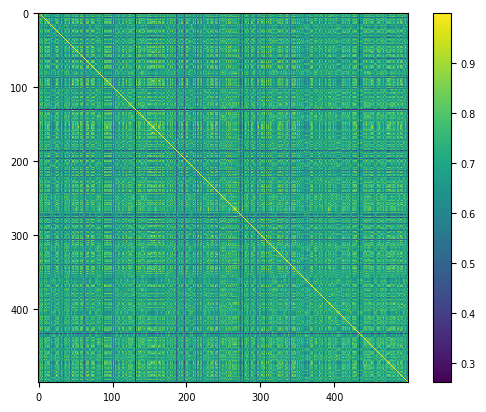

In [8]:
from matplotlib import pyplot as plt
ttt = embedding.reshape(embedding.shape[0], -1).astype(jnp.float32)
ttt = ttt @ ttt.T / (jnp.linalg.norm(ttt, axis=1, keepdims=True) @ jnp.linalg.norm(ttt, axis=1, keepdims=True).T)
plt.imshow(np.array(ttt, dtype=np.float32), interpolation='nearest')
plt.colorbar()

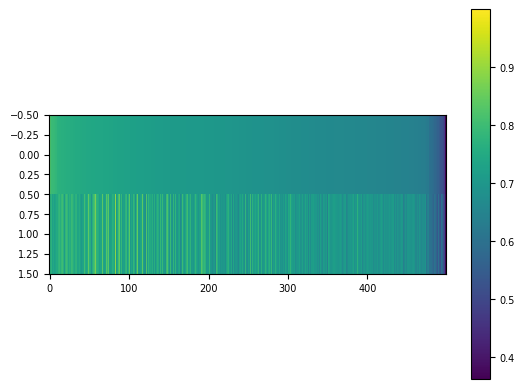

In [9]:
idx = jnp.argsort(ttt[0])[::-1]
plt.imshow(np.array(ttt[0:2,idx], dtype=np.float32), aspect=100, interpolation='nearest')
plt.colorbar()


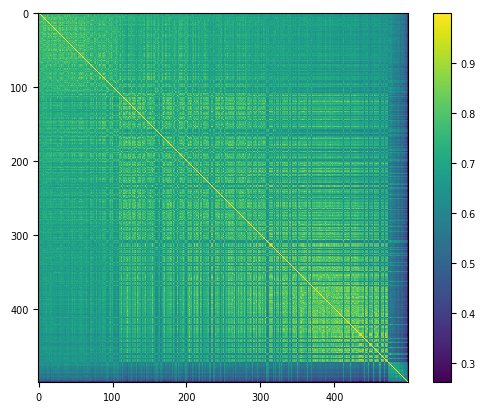

In [10]:
idx = np.argsort(ttt[0])[::-1]
plt.imshow(np.array(ttt[idx][:,idx], dtype=np.float32), aspect=1, interpolation='nearest')
plt.colorbar()


In [20]:
from scipy.cluster.hierarchy import linkage, dendrogram, optimal_leaf_ordering
from scipy.spatial.distance import squareform

# similarity matrix: sim (500×500)
dist = 1 - ttt
# dist = dist.at[range(dist.shape[0]), range(dist.shape[0])].set(0.0)  # zero diagonal
# dist = 0.5 * (dist + dist.T)  # make sure distance is symmetric
# jnp.diagonal(dist).set(0.0)

# convert to condensed vector form
condensed = squareform(dist, checks=False)

Z = linkage(condensed, method='average')
Z_opt = optimal_leaf_ordering(Z, condensed)

order = dendrogram(Z_opt, no_plot=True)['leaves']


In [21]:
condensed.shape

(124750,)

<Axes: >

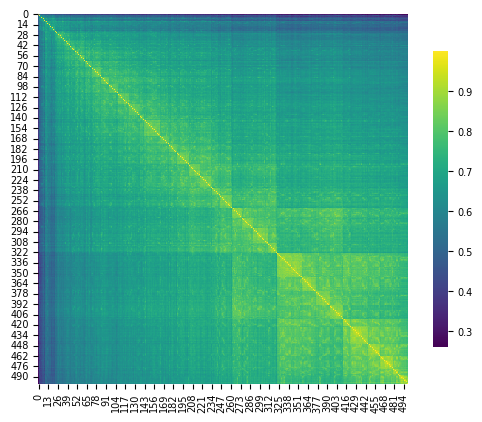

In [22]:
import seaborn as sns
# plt.figure(figsize=(6,6))
sns.heatmap(np.array(ttt[np.array(order)][:, order], dtype=np.float32), cmap="viridis", square=True, cbar_kws={"shrink": .8})

<Axes: >

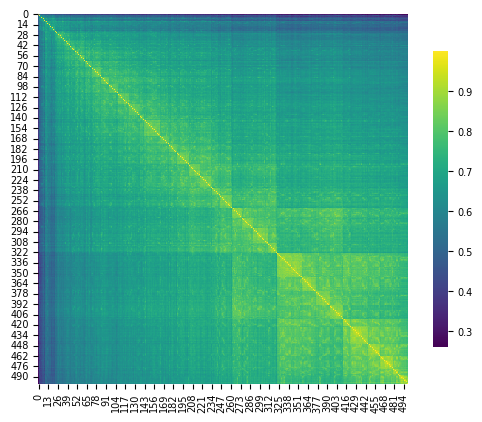

In [14]:
import seaborn as sns
# plt.figure(figsize=(6,6))
sns.heatmap(np.array(ttt[np.array(order)][:, order], dtype=np.float32), cmap="viridis", square=True, cbar_kws={"shrink": .8})

<Axes: >

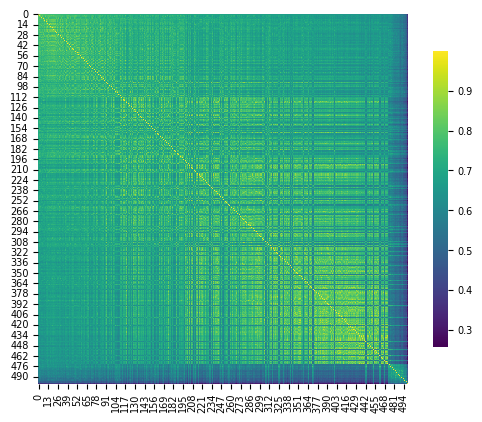

In [57]:
tttt = hidden_states.reshape(hidden_states.shape[0], -1).astype(jnp.float32)[np.array(idx)]
tttt = tttt @ tttt.T / (jnp.linalg.norm(tttt, axis=1, keepdims=True) @ jnp.linalg.norm(tttt, axis=1, keepdims=True).T)
sns.heatmap(np.array(tttt, dtype=np.float32), cmap="viridis", square=True, cbar_kws={"shrink": .8})

<Axes: >

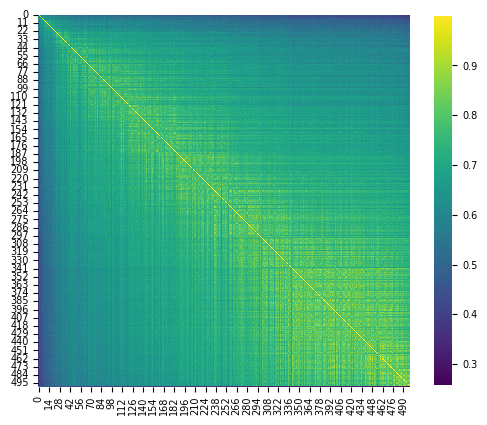

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# similarity matrix: sim (500x500)

# Schritt 1: Similarity → Distance
dist = 1 - ttt

# Schritt 2: Eine Weight-Matrix erstellen (z. B. ähnlich wie sim)
W = dist.copy()

# Schritt 3: Gradientenmatrix D
D = np.diag(dist.sum(axis=1))

# Schritt 4: Laplacian L
L = D - W

# Schritt 5: Eigenvektoren holen
vals, vecs = jnp.linalg.eigh(L)

# Schritt 6: Fiedler vector (zweiter kleinster Eigenwert)
fiedler = vecs[:, -2]

# Schritt 7: Sortierung nach Fiedler-Vektor
order = np.argsort(fiedler)

# Schritt 8: sortierte Matrix
sim_sorted = ttt[order][:, order]

# Schritt 9: Heatmap
plt.figure(figsize=(6, 6))
sns.heatmap(sim_sorted, cmap="viridis", square=True, cbar_kws={"shrink": .8})


In [114]:
jax.random.permutation(jax.random.PRNGKey(1), 10)

Array([7, 6, 3, 2, 0, 8, 1, 5, 9, 4], dtype=int32)

In [74]:
for inp, label in zip(input_ids[order][:10], target_id[order][:10]):
    print("Input:", tokenizer.decode(inp, skip_special_tokens=True))
    print("Label:", tokenizer.decode(label, skip_special_tokens=True))
    print("-----")

Input: Return the label of the correct answer for the question below.

Question: Science fact: a cavern is formed by carbonic acid in groundwater seeping through rock and dissolving
Chioces:
sedimentary rock which is  composed mainly of skeletal fragments of marine organisms such as coral, forams and molluscs,) A
metamorphic rocks that are formed under the surface of the earth from the metamorphosis,) B
igneous rocks which are formed when magma  cools and hardens or) C
artist who play the music genre called rock and roll.) D
Answer:
Label: A
-----
Input: Return the label of the correct answer for the question below.

Question: Recently, a lot of people, en masse, were told that they should take an opportunity to cast an image of an object through a pinhole onto a screen, in order to best enjoy an activity. This was because
Chioces:
scientists are lacking fun) A
eclipses are best to look at directly) B
science tells us eclipses are scary) C
avoiding looking directly at an eclipse is imp

In [11]:
hidden_states.shape

(500, 127, 896)

In [13]:
jnp.argmax(ttt[0,1:])

Array(197, dtype=int32)

In [15]:
print(tokenizer.decode(input_ids[0], skip_special_tokens=True))
print("Label:", tokenizer.decode(target_id[0], skip_special_tokens=True))

max_idx = jnp.argmax(ttt[0,1:])
print(tokenizer.decode(input_ids[max_idx], skip_special_tokens=True))
print("Label:", tokenizer.decode(target_id[max_idx], skip_special_tokens=True))

Return the label of the correct answer for the question below.

Question: Frilled sharks and angler fish live far beneath the surface of the ocean, which is why they are known as
Chioces:
Deep sea animals) A
fish) B
Long Sea Fish) C
Far Sea Animals) D
Answer:
Label: A
Return the label of the correct answer for the question below.

Question: Some fish species, when hunting, will lurk in the shallowest portions of water and actually leave the water in order to capture prey. These fish are able to hunt in this fashion after years of
Chioces:
training in a school) A
adapting to their needs) B
adapting to new music) C
wishing for it to work) D
Answer:
Label: B


In [36]:
print(tokenizer.decode(input_ids[2], skip_special_tokens=True))
print("Label:", tokenizer.decode(target_id[2], skip_special_tokens=True))

print(tokenizer.decode(input_ids[8], skip_special_tokens=True))
print("Label:", tokenizer.decode(target_id[8], skip_special_tokens=True))

Return the label of the correct answer for the question below.

Question: They were worried the wine would ruin the bed and the blanket, but the _ was't ruined.
Choices:
A) blanket
B) bed
Answer:
Label: B
Return the label of the correct answer for the question below.

Question: Natalie has a rich husband and lots of money, Jennifer is poor _ needs to make her clothes.
Choices:
A) Natalie
B) Jennifer
Answer:
Label: B


#### dataset sampling

In [28]:
from jax import random
import jax.numpy as jnp
import jax

rng_key = random.PRNGKey(0)
x_all = jnp.arange(0,100).reshape(-1,10).astype(jnp.float32)
window_size = 4
batch_size = 4


rng_key, subkey = random.split(rng_key)
t = random.uniform(subkey, (1,), minval=0., maxval=1.)
t=.2
# get batch from data
pos = jnp.round(t*x_all.shape[0]).squeeze().astype(int)
rng_key, subkey = random.split(rng_key)
idx = jax.random.choice(subkey, window_size, shape=(batch_size,), replace=False) + pos - window_size//2
idx %= x_all.shape[0]
# idx = jnp.arange(pos - window_size//2, pos + window_size//2) % x_all.shape[0]
# idx = jnp.arange(pos - window_size//2, pos + window_size//2) 
print("Idx:", idx)
x_batch = jnp.take(x_all, idx, axis=0, mode='clip', fill_value=0)

print(f"Pos:{pos}, \nx_batch:\n{x_batch}")

Idx: [3 1 0 2]
Pos:2, 
x_batch:
[[30. 31. 32. 33. 34. 35. 36. 37. 38. 39.]
 [10. 11. 12. 13. 14. 15. 16. 17. 18. 19.]
 [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9.]
 [20. 21. 22. 23. 24. 25. 26. 27. 28. 29.]]


## Bezier curve norm gradient

In [ ]:
from src.subspace_curve import bezier_curve


points = jnp.array([[0., -1.], [1., 5.], [2., 0.]])
points /= jnp.linalg.norm(points, axis=1, keepdims=True)
ts = jnp.linspace(0, 1., 5)
curve, d_curve = bezier_curve(3, points)

curve(0.5), d_curve(0.5), jax.jacrev(curve)(0.5)


(Array([0.34805807, 0.24029034], dtype=float32),
 Array([1., 1.], dtype=float32),
 Array([1., 1.], dtype=float32, weak_type=True))

In [45]:
jnp.linalg.norm(points, axis=1)

Array([1., 1., 1.], dtype=float32)

In [2]:
import numpy as np
np.exp(0.)

1.0

In [3]:
from src.subspace_curve import bezier_coeff_fn
coeff_fn = bezier_coeff_fn(3)

@jax.jacrev
def grad_to_param(params, t):
    bezier_coeff = coeff_fn(t)
    # Compute one parameter set per sample
    params_t = jnp.einsum('k,k...->...', bezier_coeff, params)
    return jnp.linalg.norm(params_t)

def gard_param_norm(points, t):
    return jnp.linalg.norm(grad_to_param(points, t), axis=-1)

key = random.PRNGKey(2)
key, subkey = random.split(key)
t_space = jax.random.uniform(key, (1000000,), minval=-0., maxval=1.)

key, subkey = random.split(key)
# points = jax.random.gamma(subkey, 2, (3, 100))
points = jax.random.beta(subkey, 2., 5., (3, 100))
# points = jax.random.gamma(subkey, 2, (3, 100))
# points /= jnp.linalg.norm(points, axis=1, keepdims=True)

p_norms = jax.vmap(gard_param_norm, in_axes=(None, 0))(points, t_space)
print(f"Average norm: {p_norms.mean(0)[0]:.4f}, {p_norms.mean(0)[1]:.4f}, {p_norms.mean(0)[2]:.4f}")

Average norm: 0.3338, 0.3334, 0.3328


(array([3.277e+03, 3.546e+03, 1.860e+03, 8.080e+02, 3.180e+02, 1.200e+02,
        4.300e+01, 1.700e+01, 9.000e+00, 2.000e+00]),
 array([6.23158459e-03, 1.18269587e+00, 2.35916018e+00, 3.53562450e+00,
        4.71208906e+00, 5.88855314e+00, 7.06501770e+00, 8.24148178e+00,
        9.41794586e+00, 1.05944109e+01, 1.17708750e+01]),
 <BarContainer object of 10 artists>)

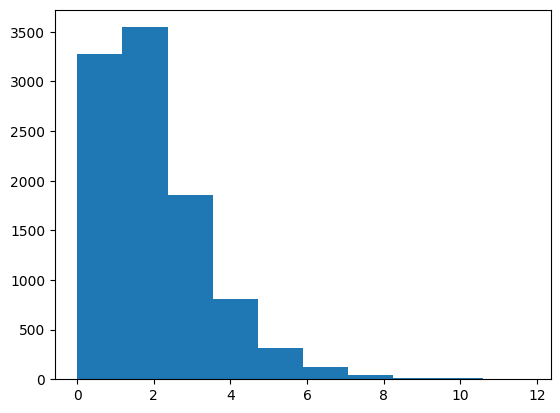

In [89]:
yy = jax.random.gamma(subkey, 2, (10000,))
plt.hist(yy)

In [71]:
p_norms2 = jax.vmap(bezier_coeff_fn(3), in_axes=(0,))(t_space)
jnp.allclose(p_norms2, p_norms)

Array(True, dtype=bool)

In [72]:
p_norms2.mean(0)

Array([0.33399186, 0.33299896, 0.33300918], dtype=float32)

In [73]:
jnp.linalg.norm(grad_to_param(points, .8), axis=-1)

Array([0.04      , 0.32000002, 0.64000005], dtype=float32)

### B spline

Array([0.25, 0.5 , 0.25], dtype=float32)

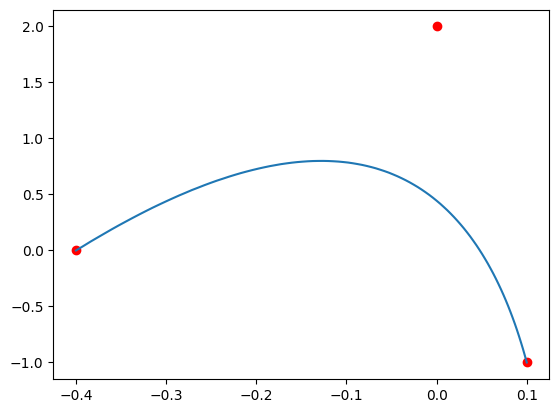

In [85]:
from src.subspace_curve import bezier_curve, bezier_coeff_fn
import matplotlib.pyplot as plt
import jax.numpy as jnp
import jax

cps = jnp.array([[-.4, 0.], [0., 2.], [.1, -1.]])

curve, d_curve = bezier_curve(3, cps)
t_space = jnp.linspace(0, 1., 100)
points_on_curve = jax.vmap(curve)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')
bezier_coeff_fn(3)(0.5)

In [136]:
from jax import custom_jvp
import jax.numpy as jnp

def bspline_basis(i, p, knots, t):
    if p == 0:
        return jnp.where(
            (knots[i] <= t) & (t < knots[i+1]), 1.0, 0.0
        )
    else:
        denom1 = knots[i+p] - knots[i]
        denom2 = knots[i+p+1] - knots[i+1]

        term1 = jnp.where(
            denom1 > 0,
            (t - knots[i]) / denom1 * bspline_basis(i, p-1, knots, t),
            0.0
        )
        term2 = jnp.where(
            denom2 > 0,
            (knots[i+p+1] - t) / denom2 * bspline_basis(i+1, p-1, knots, t),
            0.0
        )
        return term1 + term2
    
def bspline_coeff_fn(num_ctrl, degree, knots):
    # @jax.jit
    def coeff(t):
        return jnp.array([
            bspline_basis(i, degree, knots, t)
            for i in range(num_ctrl)
        ])
    return coeff

def bspline_curve(cp, degree, knots):
    num_ctrl = cp.shape[0]
    coeff_fn = bspline_coeff_fn(num_ctrl, degree, knots)

    def derivative_bspline(t):
        # analytische Ableitung der Basisfunktionen
        def dN(i):
            denom1 = knots[i+degree] - knots[i]
            denom2 = knots[i+degree+1] - knots[i+1]

            term1 = jnp.where(
                denom1 > 0,
                degree / denom1 * bspline_basis(i, degree-1, knots, t),
                0.0
            )
            term2 = jnp.where(
                denom2 > 0,
                degree / denom2 * bspline_basis(i+1, degree-1, knots, t),
                0.0
            )
            return term1 - term2

        dcoeff = jnp.array([dN(i) for i in range(num_ctrl)])
        return jnp.einsum('i,i...->...', dcoeff, cp)

    @custom_jvp
    def f(t):
        # special case: t == last knot
        t = jnp.where(
            t == knots[-1],
            t - 1e-7,   # move slightly inside
            t
        )
        coeff = coeff_fn(t)
        return jnp.einsum('i,i...->...', coeff, cp)

    def f_jvp(primals, tangents):
        t, = primals
        t_dot, = tangents
        primal_out = f(t)
        tangent_out = derivative_bspline(t)
        return primal_out, tangent_out * t_dot
    

    f.defjvp(f_jvp)
    return f, derivative_bspline

bspline_co = bspline_coeff_fn(3, 2, open_uniform_knots(3, 2))(1.)

In [130]:
def open_uniform_knots(num_ctrl, degree):
    n = num_ctrl - 1
    return jnp.concatenate([
        jnp.zeros(degree),
        jnp.linspace(0, 1, n - degree + 2),
        jnp.ones(degree)
    ])

In [131]:
bspline_co = bspline_coeff_fn(3, 2, open_uniform_knots(3, 2))
bspline_co(1.-1e-7)

Array([1.4210855e-14, 2.3841855e-07, 9.9999976e-01], dtype=float32)

In [132]:
open_uniform_knots(3, 2)    

Array([0., 0., 0., 1., 1., 1.], dtype=float32)

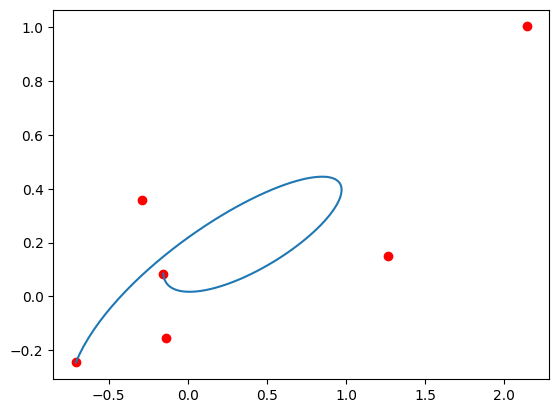

In [133]:
degree = 5
knots = open_uniform_knots(cps.shape[0], degree)
# knots = np.array([0., 0., 1., 1., 1., 1.])
# knots = np.array([0., 0.2, 0.4, 0.6, 0.8, 1.])
bspline,_ = bspline_curve(cps, degree, knots)
t_space = jnp.linspace(0, 1.-1e-7, 100)
points_on_curve = jax.vmap(bspline)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

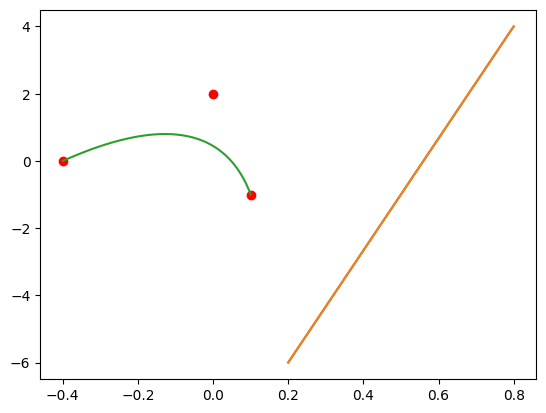

In [67]:
d_b = jax.vmap(jax.jacrev(bspline))(t_space)
d_bezier = jax.vmap(jax.jacrev(curve))(t_space)
plt.plot(d_b[:,0], d_b[:,1])
plt.plot(d_bezier[:,0], d_bezier[:,1])
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

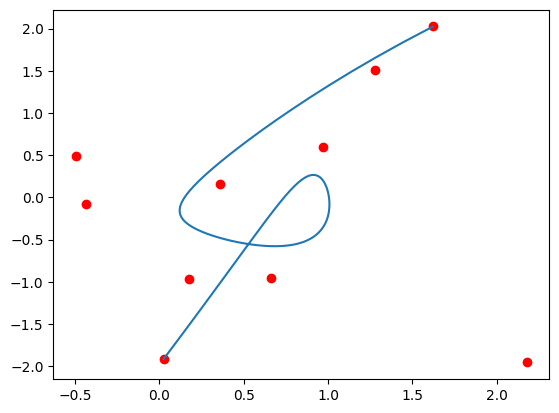

In [141]:
cps = jax.random.normal(random.PRNGKey(0), (10,2))
degree = 2
knots = open_uniform_knots(cps.shape[0], degree)
bspline, _ = bspline_curve(cps, degree, knots)
t_space = jnp.linspace(0, 1.-1e-7, 100)
points_on_curve = jax.vmap(bspline)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

In [ ]:
# def bspline_basis_all(t, knots, degree):
#     m = knots.shape[0] - 1
#     n = m - degree - 1  # number of basis functions

#     # degree 0
#     N = jnp.where(
#         (knots[:-1] <= t) & (t < knots[1:]),
#         1.0,
#         0.0
#     )[:n]

#     def body(N, p):
#         left_denom = knots[p:p+n] - knots[:n]
#         right_denom = knots[p+1:p+n+1] - knots[1:n+1]

#         left = jnp.where(
#             left_denom > 0,
#             (t - knots[:n]) / left_denom * N,
#             0.0
#         )

#         right = jnp.where(
#             right_denom > 0,
#             (knots[p+1:p+n+1] - t) / right_denom * jnp.roll(N, -1),
#             0.0
#         )

#         return left + right, None

#     N, _ = jax.lax.scan(body, N, jnp.arange(1, degree + 1))
#     return N

import jax
import jax.numpy as jnp


# still wrong implementation for degree < num_ctrl-2
def bspline_basis_all(t, knots, degree):
    """
    Returns all N_{i,degree}(t)
    Shape: (num_ctrl,)
    """
    num_ctrl = knots.shape[0] - degree - 1

    # degree 0
    N = jnp.where(
        (knots[:-1] <= t) & (t < knots[1:]),
        1.0,
        0.0
    )[:num_ctrl]

    def body(N, _):
        left_denom  = knots[degree:degree+num_ctrl] - knots[:num_ctrl]
        right_denom = knots[degree+1:degree+1+num_ctrl] - knots[1:num_ctrl+1]

        left = jnp.where(
            left_denom > 0,
            (t - knots[:num_ctrl]) / left_denom * N,
            0.0
        )

        right = jnp.where(
            right_denom > 0,
            (knots[degree+1:degree+1+num_ctrl] - t) / right_denom * jnp.roll(N, -1),
            0.0
        )

        return left + right, None

    N, _ = jax.lax.scan(body, N, None, length=degree)
    return N



def bspline_derivative_coeff(t, knots, degree):
    N = bspline_basis_all(t, knots, degree - 1)

    left_denom = knots[degree:-1] - knots[:-degree-1]
    right_denom = knots[degree+1:] - knots[1:-degree]

    term1 = jnp.where(left_denom > 0, degree / left_denom * N[:-1], 0.0)
    term2 = jnp.where(right_denom > 0, degree / right_denom * N[1:], 0.0)

    return term1 - term2

def bspline_curve(cp, degree, knots):
    num_ctrl = cp.shape[0]

    def derivative_bspline(t):
        dcoeff = bspline_derivative_coeff(t, knots, degree)
        return jnp.einsum('i,i...->...', dcoeff[:num_ctrl], cp)

    @custom_jvp
    def f(t):
        coeff = bspline_basis_all(t, knots, degree)[:num_ctrl]
        return jnp.einsum('i,i...->...', coeff, cp)

    def f_jvp(primals, tangents):
        (t,) = primals
        (t_dot,) = tangents
        primal = f(t)
        tangent = derivative_bspline(t)
        return primal, tangent * t_dot

    f.defjvp(f_jvp)
    return f, derivative_bspline



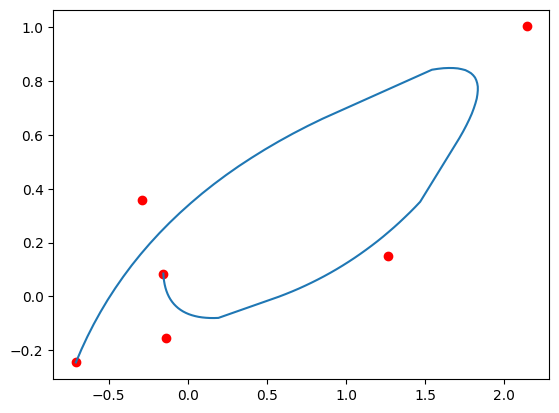

In [118]:

cps = jax.random.normal(random.PRNGKey(1), (6,2))
degree = 2
knots = open_uniform_knots(cps.shape[0], degree)
bspline,_ = bspline_curve(cps, degree, knots)
t_space = jnp.linspace(0, 1.-1e-7, 100)
points_on_curve = jax.vmap(bspline)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

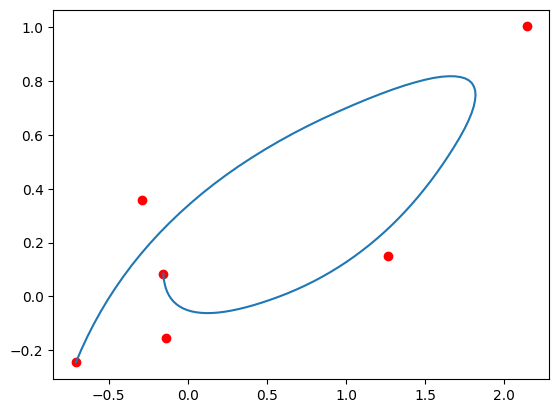

In [115]:

cps = jax.random.normal(random.PRNGKey(1), (6,2))
degree = 2
knots = open_uniform_knots(cps.shape[0], degree)
bspline,_ = bspline_curve(cps, degree, knots)
t_space = jnp.linspace(0, 1.-1e-7, 100)
points_on_curve = jax.vmap(bspline)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

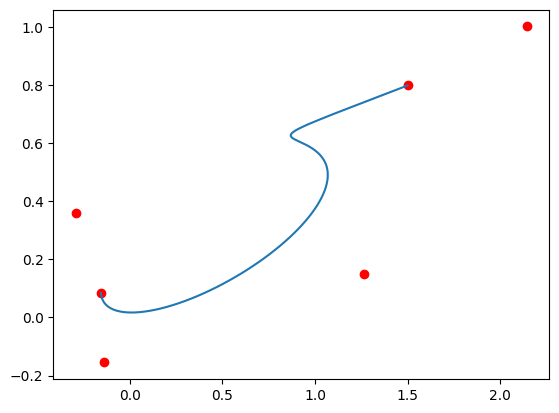

In [106]:

cps = jax.random.normal(random.PRNGKey(1), (6,2))
cps = cps.at[-1].set((1.5,0.8))
degree = 5
knots = open_uniform_knots(cps.shape[0], degree)
bspline,_ = bspline_curve(cps, degree, knots)
t_space = jnp.linspace(0, 1.-1e-7, 100)
points_on_curve = jax.vmap(bspline)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

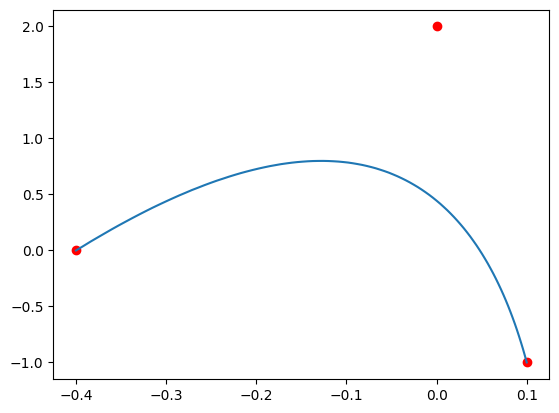

In [108]:
degree = 2

cps = jnp.array([[-.4, 0.], [0., 2.], [.1, -1.]])
knots = open_uniform_knots(cps.shape[0], degree)
# knots = np.array([0., 0., 1., 1., 1., 1.])
bspline,_ = bspline_curve(cps, degree, knots)
t_space = jnp.linspace(0, 1.-1e-7, 100)
points_on_curve = jax.vmap(bspline)(t_space)
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')

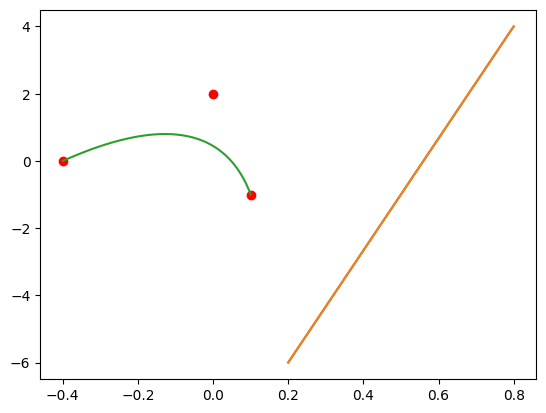

In [109]:
d_b = jax.vmap(jax.jacrev(bspline))(t_space)
d_bezier = jax.vmap(jax.jacrev(curve))(t_space)
plt.plot(d_b[:,0], d_b[:,1])
plt.plot(d_bezier[:,0], d_bezier[:,1])
plt.plot(points_on_curve[:,0], points_on_curve[:,1])
plt.scatter(cps[:,0], cps[:,1], color='red')